# Predicting Wine Quality Using Machine Learning
- *Project by*: Genevieve Orr, Anna Phipps, Ellie Roberts, Hayden Gamble
- *Course*: ENGR:3110 Introduction to AI and Machine Learning

## Introduction:
Our goal for this project is to develop and evaluate different machine learning regression models to predict the quality of wine based on its physiochemical properties. The dataset contains 4898 wine samples and 11 input features. We will test the different models on a training set to determine which one works best at predicting wine quality.

## Methods: Data
- Our project uses **regression** to predict a wine's numerical quality score based on its physicochemical properties. The quality scores are treated as numerical values rather than separate categories.

- We used the [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) dataset, specifically the white wine data, containing `4,898 samples` with `11 numerical features` describing the wine's physicochemical properties. Our target variable is the wine's quality score.

- We loaded the dataset using Pandas and checked for missing values and duplicate rows. No missing values were found, but `937 duplicate rows` were removed, leaving `3,961 samples`. We also examined summary statistics and plotted the distribution of quality scores.

- Finally, we separated the input features from the target variable and split the cleaned dataset into `60% training`, `20% validation`, and `20% testing`. We used stratified splitting to maintain similar quality-score distributions across the sets and random_state=42 for reproducibility. The test set will be reserved for evaluating the final selected model.


Original dataset shape (rows, columns): (4898, 12)
Number of missing values: 0
Exact duplicate rows: 937
Data types:
 fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6



Dataset shape after removing duplicate rows: (3961, 12)


,count,mean,std,min,25%,50%,75%,max
fixed acidity,3961.0,6.839346,0.866860,3.80000,6.30000,6.8000,7.30000,14.20000
volatile acidity,3961.0,0.280538,0.103437,0.08000,0.21000,0.2600,0.33000,1.10000
citric acid,3961.0,0.334332,0.122446,0.00000,0.27000,0.3200,0.39000,1.66000
residual sugar,3961.0,5.914819,4.861646,0.60000,1.60000,4.7000,8.90000,65.80000
chlorides,3961.0,0.045905,0.023103,0.00900,0.03500,0.0420,0.05000,0.34600
free sulfur dioxide,3961.0,34.889169,17.210021,2.00000,23.00000,33.0000,45.00000,289.00000
total sulfur dioxide,3961.0,137.193512,43.129065,9.00000,106.00000,133.0000,166.00000,440.00000
density,3961.0,0.993790,0.002905,0.98711,0.99162,0.9935,0.99571,1.03898
pH,3961.0,3.195458,0.151546,2.72000,3.09000,3.1800,3.29000,3.82000
sulphates,3961.0,0.490351,0.113523,0.22000,0.41000,0.4800,0.55000,1.08000



Wine quality counts after cleaning:
 quality
3      20
4     153
5    1175
6    1788
7     689
8     131
9       5
Name: count, dtype: int64


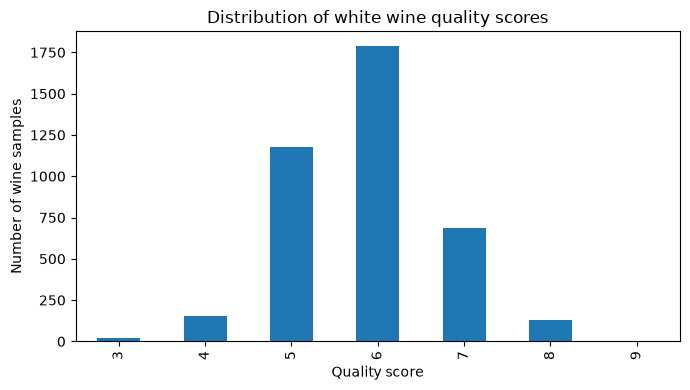


Final data split sizes:
Training:   2376 rows, 11 features
Validation: 792 rows, 11 features
Testing:    793 rows, 11 features


In [1]:
## imports
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd
import seaborn as sns
from sklearn import (datasets, neighbors,
                     naive_bayes,
                     model_selection as skms,
                     linear_model, metrics)
from pathlib import Path

# Load data and create the shared splits - Hayden
csv_path = Path("winequality-white.csv")
wine_df = pd.read_csv(csv_path, sep=";")

print("Original dataset shape (rows, columns):", wine_df.shape)
print("Number of missing values:", wine_df.isna().sum().sum())
print("Exact duplicate rows:", wine_df.duplicated().sum())
print("Data types:\n", wine_df.dtypes)
display(wine_df.head())

# Remove identical full rows so the same observation cannot appear in both training and testing
wine_df = wine_df.drop_duplicates().reset_index(drop=True)
print("\nDataset shape after removing duplicate rows:", wine_df.shape)

# Descriptive summary and distribution of recorded quality scores.
display(wine_df.describe().T)
quality_counts = wine_df["quality"].value_counts().sort_index()
print("\nWine quality counts after cleaning:\n", quality_counts)

fig, ax = plt.subplots(figsize=(7, 4))
quality_counts.plot(kind="bar", ax=ax)
ax.set_title("Distribution of white wine quality scores")
ax.set_xlabel("Quality score")
ax.set_ylabel("Number of wine samples")
plt.tight_layout()
plt.show()

# Separate the 11 feature columns from the quality target.
X = wine_df.drop(columns=["quality"])
y = wine_df["quality"]

# First reserve 20% for the untouched final test set.
X_train_val, X_test, y_train_val, y_test = skms.train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# From the remaining 80%, use 25% for validation (20% of all rows).
# Final proportions: 60% train, 20% validation, 20% test.
X_train, X_val, y_train, y_val = skms.train_test_split(
    X_train_val, y_train_val, test_size=0.25,
    random_state=42, stratify=y_train_val
)

print("\nFinal data split sizes:")
print(f"Training:   {len(X_train)} rows, {X_train.shape[1]} features")
print(f"Validation: {len(X_val)} rows, {X_val.shape[1]} features")
print(f"Testing:    {len(X_test)} rows, {X_test.shape[1]} features")


## Methods: Training/Validation
- Linear Regression
    - All Features
        - ```Text here```
    - Reduced Feature Set
        - ```Text here```
- KNN Regression
    - `k = 3`
        - We use *K-Nearest Neighbors Regression* with `k = 3` to predict wine quality from the average quality score of the three most similar training wines. Since KNN uses distances, we standardize the 11 features with `StandardScaler` in a pipeline fitted only on the training data. We then evaluate the model on the validation set using RMSE, MAE, and R². The test set is not used in this step.
    - `k = 7`
        - ```Text here```
    - `k = 11`
        - We use K-Nearest Neighbors Regression with k = 11 to predict wine quality based on the 11 physiochemical features in our dataset. The model identifies the 11 wines with the most similar characteristics and uses the most common quality rating to make its prediction. We then evaluate the model on the validation set using RMSE and compare it with other models.

In [2]:
# use training set to evaluate models
# Linear regression (all features) - Anna



In [3]:
# Linear regression (reduced feature set) - Anna


In [10]:
# KNN Regression (k=3) - Hayden
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor

# Scaling is learned from X_train only; X_val is transformed using that same scaler.
knn3_model = make_pipeline(
    StandardScaler(),
    KNeighborsRegressor(n_neighbors=3)
)

# Fit on the training set and predict wine quality on the validation set.
knn3_model.fit(X_train, y_train)
knn3_val_predictions = knn3_model.predict(X_val)

# Regression metrics for comparison with the other models (lower RMSE/MAE is better).
knn3_val_rmse = np.sqrt(metrics.mean_squared_error(y_val, knn3_val_predictions))
knn3_val_mae = metrics.mean_absolute_error(y_val, knn3_val_predictions)
knn3_val_r2 = metrics.r2_score(y_val, knn3_val_predictions)

knn3_results = {
    "Model": "KNN Regression (k=3)",
    "Validation RMSE": knn3_val_rmse,
    "Validation MAE": knn3_val_mae,
    "Validation R2": knn3_val_r2,
}
display(pd.DataFrame([knn3_results]).round(3))


,Model,Validation RMSE,Validation MAE,Validation R2
0,KNN Regression (k=3),0.811,0.61,0.172


In [11]:
# kNN (k=7) - Ellie


In [12]:
# kNN (k=11) - Gen

# create model
knn11_model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=11))

# model training and predictions
knn11_model.fit(X_train, y_train)
knn11_val_predictions = knn11_model.predict(X_val)

# calculate rmse
knn11_val_rmse = np.sqrt(metrics.mean_squared_error(y_val, knn11_val_predictions))

knn11_results = {
    "Model": "kNN Regression (k=11)",
    "Validation RMSE": knn11_val_rmse
}
display(pd.DataFrame([knn11_results]).round(3))


,Model,Validation RMSE
0,kNN Regression (k=11),0.755


## Determining Best Model


In [19]:
# Comparing validation accuracies in models - Ellie


## Results on Test Set

In [20]:
# use test set to test final model - Gen


## Discussion/Conclusion


## Disclosures